In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Definir los nombres de las columnas
columns = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

# Cargar el dataset acomodando espacios y nulos
url = "adult.csv"

#'skipinitialspace=True' elimina los espacios molestos después de las comas,
# lo que permite que 'na_values="?"' detecte los valores faltantes correctamente.
df = pd.read_csv(url, na_values="?", skipinitialspace=True)

# Inspeccionar el tipo de atributo y los datos faltantes
print("--- Información general del Dataset ---")
df.info()

print("\n--- Columnas con nulos ---")
print(df.isnull().sum())

# Eliminar las filas con valores faltantes (NaN)
df_cleaned = df.dropna()

print("\n--- Resultado de la limpieza ---")
print(f"Filas originales: {df.shape[0]} | Filas tras eliminar faltantes: {df_cleaned.shape[0]}")

# Sobrescribir el dataframe original con el limpio
df = df_cleaned

# Eliminamos columnas que no aportan informacion o son redundantes
df = df.drop(columns=["fnlwgt", "education"])
print("\nColumnas restantes:", df.columns.tolist())





--- Información general del Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16281 entries, 0 to 16280
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             16281 non-null  int64 
 1   workclass       15318 non-null  object
 2   fnlwgt          16281 non-null  int64 
 3   education       16281 non-null  object
 4   education-num   16281 non-null  int64 
 5   marital-status  16281 non-null  object
 6   occupation      15315 non-null  object
 7   relationship    16281 non-null  object
 8   race            16281 non-null  object
 9   sex             16281 non-null  object
 10  capital-gain    16281 non-null  int64 
 11  capital-loss    16281 non-null  int64 
 12  hours-per-week  16281 non-null  int64 
 13  native-country  16007 non-null  object
 14  income          16281 non-null  object
dtypes: int64(6), object(9)
memory usage: 1.9+ MB

--- Columnas con nulos ---
age                 0
wor


--Resumen estadístico de las variables numéricas ---
            age  education-num  capital-gain  capital-loss  hours-per-week
count  15060.00       15060.00      15060.00      15060.00        15060.00
mean      38.77          10.11       1120.30         89.04           40.95
std       13.38           2.56       7703.18        406.28           12.06
min       17.00           1.00          0.00          0.00            1.00
25%       28.00           9.00          0.00          0.00           40.00
50%       37.00          10.00          0.00          0.00           40.00
75%       48.00          13.00          0.00          0.00           45.00
max       90.00          16.00      99999.00       3770.00           99.00

-- Distribución de Género ---
sex
Male      67.38%
Female    32.62%
------------------------------

--- Distribución de Clase de Trabajo ---
workclass
Private             73.18
Self-emp-not-inc     8.61
Local-gov            6.86
State-gov            4.43
Self-emp-inc   

/tmp/ipykernel_2150/3195555833.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sex_freq.index, y=sex_freq.values, ax=axes[0, 0], palette="Blues_r")
/tmp/ipykernel_2150/3195555833.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=workclass_freq.values, y=workclass_freq.index, ax=axes[0, 1], palette="Greens_r")
/tmp/ipykernel_2150/3195555833.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=income_freq.index, y=income_freq.values, ax=axes[1, 0], palette="Oranges_r")



--- Distribución de la Variable Objetivo (income) ---
income
<=50K.    75.43
>50K.     24.57
------------------------------

--- Distribución de Origen (USA vs Otros) ---
United-States    91.55
Otros Países      8.45
------------------------------


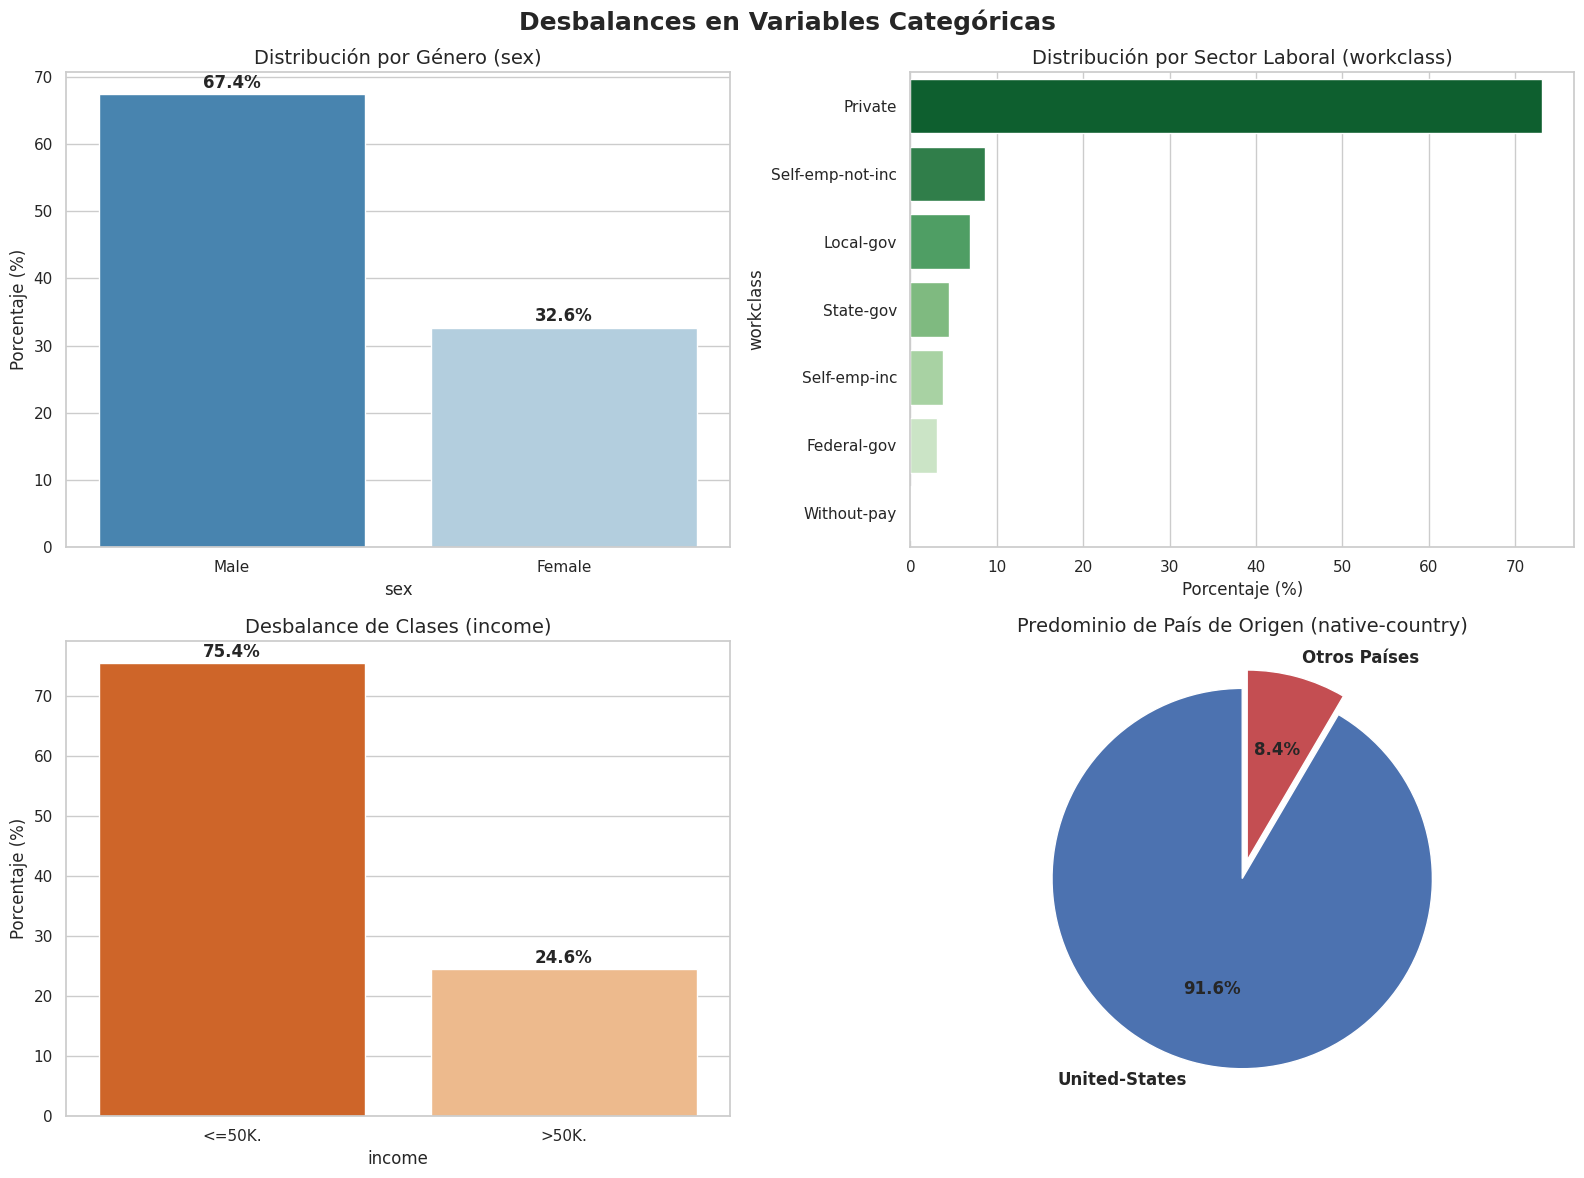

In [7]:
print("\n--Resumen estadístico de las variables numéricas ---")
sns.set_theme(style="whitegrid")
print(df.describe().round(2), )

# Estadisticas de variables Categóricas
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Desbalances en Variables Categóricas ", fontsize=18, fontweight='bold')

# --- 1. DESBALANCE DE GÉNERO (sex) ---
sex_freq = df['sex'].value_counts(normalize=True) * 100
print("\n-- Distribución de Género ---")
# Aplicamos el formato de porcentaje directamente a la serie antes del to_string
print(sex_freq.round(2).map("{:.2f}%".format).to_string())
print("-" * 30)

sns.barplot(x=sex_freq.index, y=sex_freq.values, ax=axes[0, 0], palette="Blues_r")
axes[0, 0].set_title("Distribución por Género (sex)", fontsize=14)
axes[0, 0].set_ylabel("Porcentaje (%)")
for i, v in enumerate(sex_freq.values):
    axes[0, 0].text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')

# --- 2. PREDOMINIO DEL SECTOR PRIVADO (workclass) ---
# Limpiamos posibles valores faltantes "?" si los hubiera, para ver la distribución real de los conocidos
workclass_freq = df['workclass'].value_counts(normalize=True) * 100
print("\n--- Distribución de Clase de Trabajo ---")
print(workclass_freq.round(2).to_string())
print("-" * 30)

sns.barplot(x=workclass_freq.values, y=workclass_freq.index, ax=axes[0, 1], palette="Greens_r")
axes[0, 1].set_title("Distribución por Sector Laboral (workclass)", fontsize=14)
axes[0, 1].set_xlabel("Porcentaje (%)")

# --- 3. VARIABLE OBJETIVO (income) ---
income_freq = df['income'].value_counts(normalize=True) * 100
print("\n--- Distribución de la Variable Objetivo (income) ---")
print(income_freq.round(2).to_string())
print("-" * 30)

sns.barplot(x=income_freq.index, y=income_freq.values, ax=axes[1, 0], palette="Oranges_r")
axes[1, 0].set_title("Desbalance de Clases (income)", fontsize=14)
axes[1, 0].set_ylabel("Porcentaje (%)")
for i, v in enumerate(income_freq.values):
    axes[1, 0].text(i, v + 1, f"{v:.1f}%", ha='center', fontweight='bold')

# --- 4. ORIGEN DEMOGRÁFICO (native-country) ---
# Agrupamos los países que no sean USA como 'Otros' para demostrar el impacto del >90%
country_counts = df['native-country'].value_counts(normalize=True) * 100
usa_vs_others = pd.Series({
    'United-States': country_counts.get('United-States', 0),
    'Otros Países': country_counts.drop('United-States', errors='ignore').sum()
})
print("\n--- Distribución de Origen (USA vs Otros) ---")
print(usa_vs_others.round(2).to_string())
print("-" * 30)

axes[1, 1].pie(usa_vs_others.values, labels=usa_vs_others.index, autopct='%1.1f%%',
               startangle=90, colors=['#4C72B0', '#C44E52'], explode=(0, 0.1),
               textprops={'fontsize': 12, 'weight': 'bold'})
axes[1, 1].set_title("Predominio de País de Origen (native-country)", fontsize=14)

# Ajustar y mostrar
plt.tight_layout()
plt.show()

/tmp/ipykernel_5679/1035190764.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='income', data=df, palette='Set2')


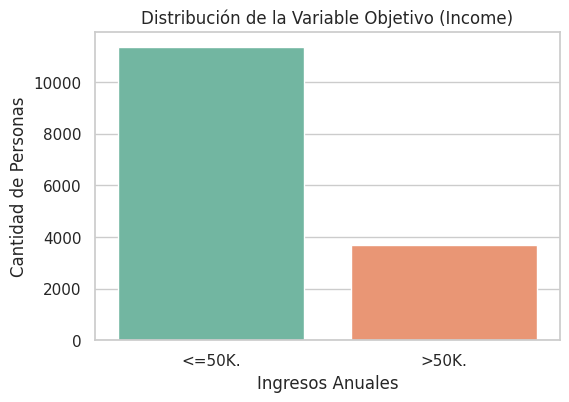

In [3]:
# DISTRIBUCION de la Variable Objetivo INCOME
plt.figure(figsize=(6, 4))
sns.countplot(x='income', data=df, palette='Set2')
plt.title('Distribución de la Variable Objetivo (Income)')
plt.xlabel('Ingresos Anuales')
plt.ylabel('Cantidad de Personas')
plt.show()

/tmp/ipykernel_5679/954716588.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='income', y='education-num', data=df, palette='Pastel1')


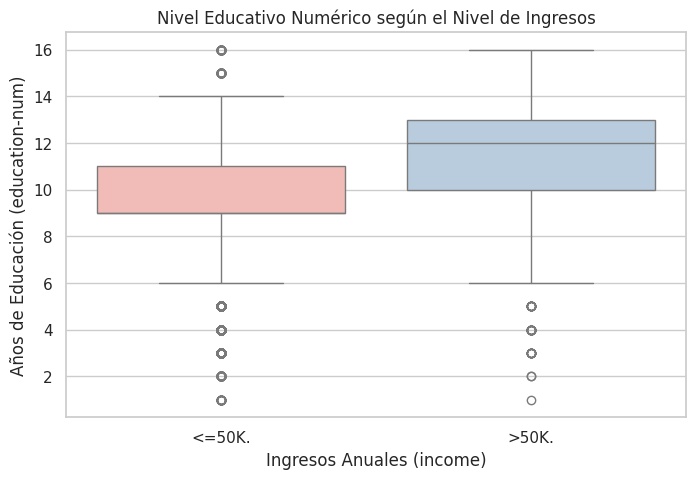

In [4]:
# Relación entre Educación e Ingresos - VISUALIZACION
plt.figure(figsize=(8, 5))
sns.boxplot(x='income', y='education-num', data=df, palette='Pastel1')
plt.title('Nivel Educativo Numérico según el Nivel de Ingresos')
plt.xlabel('Ingresos Anuales (income)')
plt.ylabel('Años de Educación (education-num)')
plt.show()


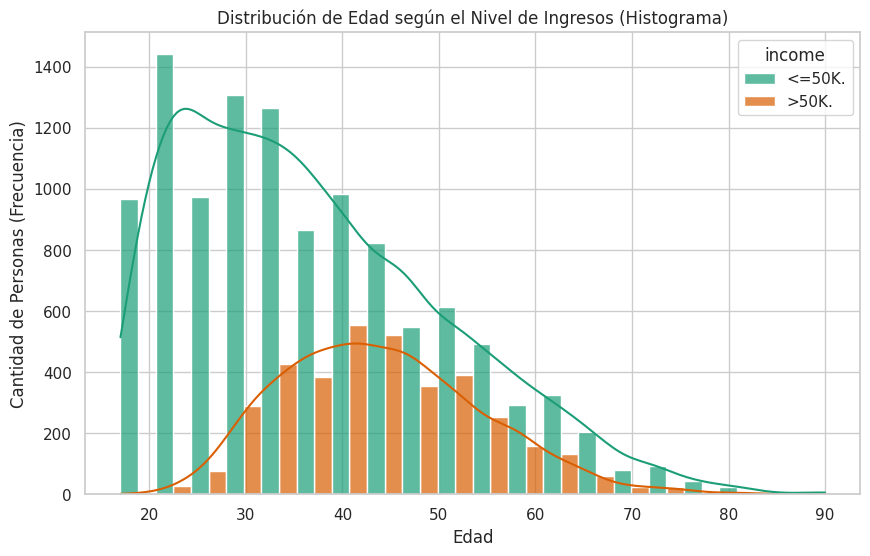

In [5]:
# Relación entre Edad e Ingresos - VISUALIZACION
plt.figure(figsize=(10, 6))

# 'multiple="dodge"' coloca las barras lado a lado.
# 'bins=20' agrupa las edades en 20 bloques (puedes ajustar este número)
sns.histplot(
    data=df,
    x='age',
    hue='income',
    fill=True,
    multiple="dodge",
    bins=20,
    palette='Dark2',
    alpha=0.7,
    kde=True # dibuja la línea de densidad sobre el histograma
)

plt.title('Distribución de Edad según el Nivel de Ingresos (Histograma)')
plt.xlabel('Edad')
plt.ylabel('Cantidad de Personas (Frecuencia)')
plt.show()

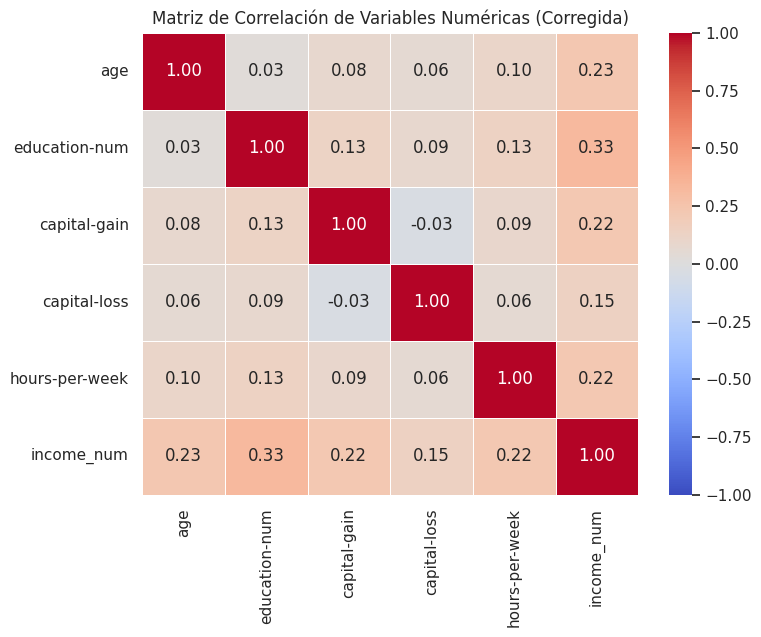

In [6]:
# CORRELACIONES en atributos numericos
# Aseguramos la transformación limpia de la columna (sin espacios)
df['income_num'] = df['income'].str.strip().map({'<=50K.': 0, '>50K.': 1})

# Seleccionamos las columnas numéricas incluyendo la nueva
columnas_interes = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week', 'income_num']

# Calculamos la matriz eliminando cualquier fila que haya quedado con NaN en ese mapeo
matriz_corregida = df[columnas_interes].dropna().corr()

# Graficas de nuevo
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corregida, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Matriz de Correlación de Variables Numéricas (Corregida)')
plt.show()

In [7]:
# Calcular el desbalance de Género
print("--- Distribución por Género ---")
print(df['sex'].value_counts(normalize=True) * 100)

# Calcular el desbalance de Raza
print("\n--- Distribución por Raza ---")
print(df['race'].value_counts(normalize=True) * 100)

# Calcular el desbalance de País Nativo
print("\n--- Distribución por País Nativo ---")
print(df['native-country'].value_counts(normalize=True).head(3) * 100)

--- Distribución por Género ---
sex
Male      67.377158
Female    32.622842
Name: proportion, dtype: float64

--- Distribución por Raza ---
race
White                 86.122178
Black                  9.369190
Asian-Pac-Islander     2.709163
Amer-Indian-Eskimo     0.989376
Other                  0.810093
Name: proportion, dtype: float64

--- Distribución por País Nativo ---
native-country
United-States    91.553785
Mexico            1.945551
Philippines       0.630810
Name: proportion, dtype: float64


In [8]:
# Calcular el desbalance de Variable Objetivo Income
print("--- Distribución por Income ---")
print(df['income'].value_counts(normalize=True) * 100)

--- Distribución por Income ---
income
<=50K.    75.431607
>50K.     24.568393
Name: proportion, dtype: float64


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


for col in ['capital-gain', 'capital-loss']:
    print(f"=== Análisis de {col} ===")
    print(df[col].describe())

    # Calcular porcentaje de ceros
    porcentaje_ceros = (df[col] == 0).mean() * 100
    # Calcular cuántos están en el valor máximo
    val_max = df[col].max()
    cantidad_max = (df[col] == val_max).sum()

    print(f"Porcentaje de registros en 0: {porcentaje_ceros:.2f}%")
    print(f"Cantidad de registros en el valor máximo ({val_max}): {cantidad_max}")
    print("-" * 40)

=== Análisis de capital-gain ===
count    15060.000000
mean      1120.301594
std       7703.181842
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      99999.000000
Name: capital-gain, dtype: float64
Porcentaje de registros en 0: 91.69%
Cantidad de registros en el valor máximo (99999): 81
----------------------------------------
=== Análisis de capital-loss ===
count    15060.000000
mean        89.041899
std        406.283245
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       3770.000000
Name: capital-loss, dtype: float64
Porcentaje de registros en 0: 95.27%
Cantidad de registros en el valor máximo (3770): 2
----------------------------------------


In [22]:

# Definir los límites teóricos del análisis
total_poblacion = len(df)

# Segmento A: Subempleo (1 a 10 horas)
subempleo = df[(df['hours-per-week'] >= 1) & (df['hours-per-week'] <= 10)]
cant_sub = len(subempleo)
pct_sub = (cant_sub / total_poblacion) * 100

# Segmento B: Jornada Estándar / Convencional (Referencia: 35 a 45 horas)
estandar = df[(df['hours-per-week'] >= 35) & (df['hours-per-week'] <= 45)]
cant_est = len(estandar)
pct_est = (cant_est / total_poblacion) * 100

# Segmento C: Sobreexplotación Extrema (Más de 70 horas)
sobreexplotacion = df[df['hours-per-week'] > 70]
cant_sob = len(sobreexplotacion)
pct_sob = (cant_sob / total_poblacion) * 100

# Segmento D: El techo absoluto de codificación (99 horas)
techo_99 = df[df['hours-per-week'] == 99]
cant_99 = len(techo_99)
pct_99 = (cant_99 / total_poblacion) * 100

# Imprimir reporte de hallazgos estadísticos
print("==================================================================")
print("  EVIDENCIA ESTADÍSTICA: DISTRIBUCIÓN DE JORNADAS LABORALES")
print("==================================================================")
print(f"Población Total Analizada: {total_poblacion} registros.\n")

print(f"[-] Subempleo Marginal (1-10 h/sem):")
print(f"    Muestra: {cant_sub} individuos | Proporción: {pct_sub:.2f}%")
print(f"    Rango real observado: {subempleo['hours-per-week'].min()} a {subempleo['hours-per-week'].max()} horas.\n")

print(f"[=] Jornada Convencional (35-45 h/sem):")
print(f"    Muestra: {cant_est} individuos | Proporción: {pct_est:.2f}%\n")

print(f"[+] Sobreexplotación Extrema (>70 h/sem):")
print(f"    Muestra: {cant_sob} individuos | Proporción: {pct_sob:.2f}%")
print(f"    Ingresos altos (>50K) en este grupo: {(sobreexplotacion['income'] == 1).mean()*100:.2f}%\n")

print(f"[!] Techo Técnico de Datos (Exactamente 99 h/sem):")
print(f"    Muestra: {cant_99} individuos | Proporción: {pct_99:.2f}%")
print("==================================================================")

  EVIDENCIA ESTADÍSTICA: DISTRIBUCIÓN DE JORNADAS LABORALES
Población Total Analizada: 15060 registros.

[-] Subempleo Marginal (1-10 h/sem):
    Muestra: 266 individuos | Proporción: 1.77%
    Rango real observado: 1 a 10 horas.

[=] Jornada Convencional (35-45 h/sem):
    Muestra: 9295 individuos | Proporción: 61.72%

[+] Sobreexplotación Extrema (>70 h/sem):
    Muestra: 255 individuos | Proporción: 1.69%
    Ingresos altos (>50K) en este grupo: 0.00%

[!] Techo Técnico de Datos (Exactamente 99 h/sem):
    Muestra: 45 individuos | Proporción: 0.30%


In [15]:

# 1. Definir universos de análisis
total_poblacion = len(df)
adultos_mayores = df[(df['age'] >= 75) & (df['age'] <= 90)]

cant_mayores = len(adultos_mayores)
pct_mayores = (cant_mayores / total_poblacion) * 100

# 2. Extraer insights clave de este grupo
horas_promedio_mayores = adultos_mayores['hours-per-week'].mean()
tasa_ingresos_altos = (adultos_mayores['income_num'] == 1).mean() * 100 # Cambia por 'income' si corresponde

print("==================================================================")
print("  EVIDENCIA: ADULTOS MAYORES EN ACTIVIDAD LABORAL ACTIVA")
print("==================================================================")
print(f"Población total activa de la tercera edad (75-90 años): {cant_mayores} personas")
print(f"Proporción respecto al total del dataset: {pct_mayores:.2f}%")
print(f"Promedio de horas trabajadas semanales en este grupo: {horas_promedio_mayores:.1f} horas")
print(f"Porcentaje que percibe ingresos altos (>50K): {tasa_ingresos_altos:.2f}%")
print("==================================================================")

  EVIDENCIA: ADULTOS MAYORES EN ACTIVIDAD LABORAL ACTIVA
Población total activa de la tercera edad (75-90 años): 119 personas
Proporción respecto al total del dataset: 0.79%
Promedio de horas trabajadas semanales en este grupo: 29.1 horas
Porcentaje que percibe ingresos altos (>50K): 21.01%


In [23]:
#Obtener el conteo absoluto de registros por clase de la Variable Objetivo INCOME
print("--- Conteo Absoluto de Clase ---")
conteo_absoluto = df['income'].value_counts()
print(conteo_absoluto)

#Obtener la proporción porcentual (La evidencia de la asimetría)
print("\n--- Proporción Porcentual (Frecuencia Relativa) ---")
proporcion_porcentual = df['income'].value_counts(normalize=True) * 100
print(proporcion_porcentual.map("{:.2f}%".format))

--- Conteo Absoluto de Clase ---
income
<=50K.    11360
>50K.      3700
Name: count, dtype: int64

--- Proporción Porcentual (Frecuencia Relativa) ---
income
<=50K.    75.43%
>50K.     24.57%
Name: proportion, dtype: object


In [8]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# Codificación binaria de la variable objetivo
df['income'] = df['income'].map({'<=50K.': 0, '>50K.': 1})

# Separación en características (X) y etiqueta objetivo (y)
X = df.drop(columns=['income'])
y = df['income']

# --- CODIFICACIÓN DE CATEGÓRICAS (ONE-HOT ENCODING) ---
# Identificamos de forma automática las columnas que son de tipo texto
categorical_cols = X.select_dtypes(include=['object']).columns
print(f'Columnas Categoricas a las que se aplicara ONE-HOT: {categorical_cols}')

# Aplicamos One-Hot Encoding convirtiendo true/false a 1/0
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True, dtype=int)

# --- DIVISIÓN ESTRATIFICADA (Mitigación del Desbalance) ---
# Usamos 'stratify=y' para mantener la proporción de las clases
# (75.5% para <=50K y 24.5% para >50K) tanto en train como en test.
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# --- ESCALADO DE VARIABLES NUMÉRICAS ---
# Escalamos únicamente las columnas que originalmente eran numéricas
numeric_cols = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

scaler = StandardScaler()
# Ajustamos con el set de entrenamiento y transformamos ambos
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

print(f"Dimensiones finales del set de entrenamiento: {X_train.shape}")

Columnas Categoricas a las que se aplicara ONE-HOT: Index(['workclass', 'marital-status', 'occupation', 'relationship', 'race',
       'sex', 'native-country'],
      dtype='object')
Dimensiones finales del set de entrenamiento: (12048, 79)


=== EVALUACIÓN: REGRESIÓN LOGÍSTICA ===
              precision    recall  f1-score   support

       <=50K       0.94      0.80      0.86      2272
        >50K       0.57      0.83      0.68       740

    accuracy                           0.81      3012
   macro avg       0.75      0.81      0.77      3012
weighted avg       0.85      0.81      0.82      3012


=== EVALUACIÓN: RANDOM FOREST ===
              precision    recall  f1-score   support

       <=50K       0.87      0.91      0.89      2272
        >50K       0.69      0.59      0.63       740

    accuracy                           0.83      3012
   macro avg       0.78      0.75      0.76      3012
weighted avg       0.83      0.83      0.83      3012



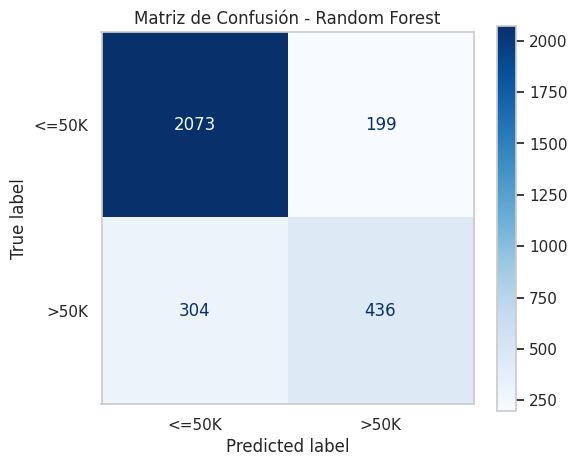

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# ==========================================
# 1. ENTRENAMIENTO DE LOS MODELOS
# ==========================================

# Modelo A: Regresión Logística
# 'class_weight="balanced"' compensa el desbalance 76/24 automáticamente
log_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_model.fit(X_train, y_train)

# Modelo B: Random Forest (Bosque Aleatorio)
rf_model = RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# ==========================================
# 2. PREDICCIONES Y EVALUACIÓN
# ==========================================

print("=== EVALUACIÓN: REGRESIÓN LOGÍSTICA ===")
y_pred_log = log_model.predict(X_test)
print(classification_report(y_test, y_pred_log, target_names=['<=50K', '>50K']))

print("\n=== EVALUACIÓN: RANDOM FOREST ===")
y_pred_rf = rf_model.predict(X_test)
print(classification_report(y_test, y_pred_rf, target_names=['<=50K', '>50K']))

# ==========================================
# 3. VISUALIZACIÓN DE LA MATRIZ DE CONFUSIÓN
# ==========================================
# Graficamos la matriz del Random Forest como ejemplo
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test, display_labels=['<=50K', '>50K'], cmap='Blues', ax=ax)
plt.title('Matriz de Confusión - Random Forest')
plt.grid(False)
plt.show()

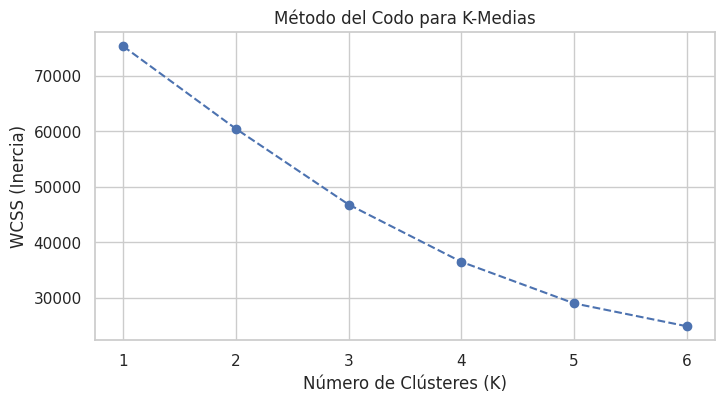


=== PERFILES DE LOS CLÚSTERES (PROMEDIOS) ===
           age  education-num  capital-gain  capital-loss  hours-per-week
Cluster                                                                  
0        38.55          10.05        614.49          0.32           40.74
1        42.16          11.08          0.00       1898.20           43.95
2        47.01          13.27      99999.00          0.00           52.01
=== DISTRIBUCIÓN DE INGRESOS POR CLÚSTER (%) ===
income        0        1
Cluster                 
0        77.18%   22.82%
1        48.72%   51.28%
2         0.00%  100.00%
--------------------------------------------------


<Figure size 1000x600 with 0 Axes>

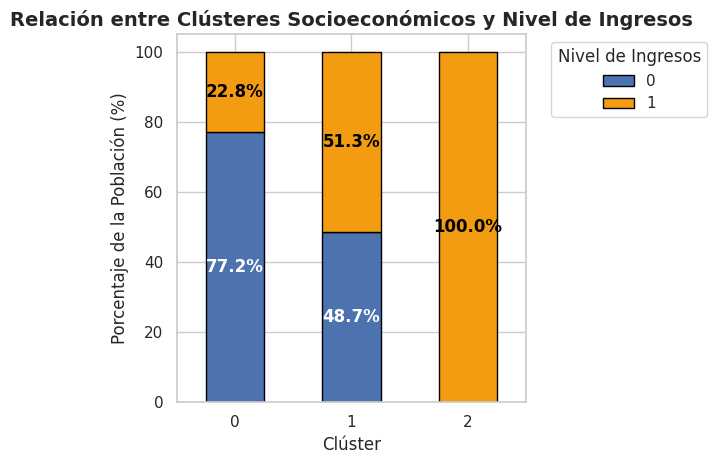

fda


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Modelo Descriptivo (Segmentación K-Medias)
# Seleccionar solo las variables numéricas clave
numeric_cols = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
X = df[numeric_cols].copy()

# Escalar los datos (Crucial para K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Determinar el número óptimo de clústeres (Método del Codo)
wcss = []
for i in range(1, 7):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Graficar el Método del Codo
plt.figure(figsize=(8, 4))
plt.plot(range(1, 7), wcss, marker='o', linestyle='--', color='b')
plt.title('Método del Codo para K-Medias')
plt.xlabel('Número de Clústeres (K)')
plt.ylabel('WCSS (Inercia)')
plt.show()

# Entrenar el modelo final (Supongamos que el codo sugiere K=3 o K=4)
# Para este dataset, K=3 suele aislar muy bien los perfiles financieros.
k_optimo = 3
kmeans_final = KMeans(n_clusters=k_optimo, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans_final.fit_transform(X_scaled).argmin(axis=1) # Asignar clústeres

#Analizar estadísticamente los perfiles creados
resumen_clusters = df.groupby('Cluster')[numeric_cols].mean()
print("\n=== PERFILES DE LOS CLÚSTERES (PROMEDIOS) ===")
print(resumen_clusters.round(2))


# Crear la tabla de contingencia (frecuencias absolutas y porcentajes)
tabla_ingresos = pd.crosstab(df['Cluster'], df['income'], normalize='index') * 100

print("=== DISTRIBUCIÓN DE INGRESOS POR CLÚSTER (%) ===")
print(tabla_ingresos.round(2).map("{:.2f}%".format))
print("-" * 50)

# 2. Visualización gráfica del cruzamiento
plt.figure(figsize=(10, 6))
tabla_ingresos.plot(kind='bar', stacked=True, color=['#4C72B0', '#F39C12'], edgecolor='black')
plt.title('Relación entre Clústeres Socioeconómicos y Nivel de Ingresos', fontsize=14, fontweight='bold')
plt.xlabel('Clúster')
plt.ylabel('Porcentaje de la Población (%)')
plt.xticks(rotation=0)
plt.legend(title='Nivel de Ingresos', bbox_to_anchor=(1.05, 1), loc='upper left')

# Añadir las etiquetas de porcentaje dentro de las barras
for i in range(len(tabla_ingresos)):
    # Porcentaje de <=50K
    val_bajo = tabla_ingresos.iloc[i, 0]
    if val_bajo > 5:
        plt.text(i, val_bajo / 2, f"{val_bajo:.1f}%", ha='center', va='center', color='white', fontweight='bold')

    # Porcentaje de >50K
    val_alto = tabla_ingresos.iloc[i, 1]
    if val_alto > 5:
        plt.text(i, val_bajo + (val_alto / 2), f"{val_alto:.1f}%", ha='center', va='center', color='black', fontweight='bold')

plt.tight_layout()
plt.show()

print("fda")